In [1]:
"""
Višeslojna neuronska mreža za predviđanje volatilnosti Microsoft akcija
Podaci: Investing.com, mesečni, 06/2016 - 06/2025
Target: Log return (mesečna volatilnost)
Predviđanje: Oktobar 2025
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance


print("=" * 60)
print("  MICROSOFT - NEURONSKA MREŽA ZA PREDVIĐANJE VOLATILNOSTI")
print("=" * 60)

df = pd.read_csv('/Users/tamaradrca/Podaci za diplomski/Microsoft Stock Price History.csv')


df.columns = ['Date', 'Price', 'Open', 'High', 'Low', 'Volume', 'Change_pct']


df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')
df = df.sort_values('Date').reset_index(drop=True)

df['Price']      = df['Price'].astype(str).str.replace(',', '').astype(float)
df['Open']       = df['Open'].astype(str).str.replace(',', '').astype(float)
df['High']       = df['High'].astype(str).str.replace(',', '').astype(float)
df['Low']        = df['Low'].astype(str).str.replace(',', '').astype(float)
df['Change_pct'] = df['Change_pct'].astype(str).str.replace('%', '').astype(float)


def parse_volume(v):
    v = str(v).strip()
    if 'B' in v:
        return float(v.replace('B', '')) * 1e9
    elif 'M' in v:
        return float(v.replace('M', '')) * 1e6
    return float(v)

df['Volume'] = df['Volume'].apply(parse_volume)

print(f"\n✓ Učitano {len(df)} mesečnih zapisa")
print(f"  Period: {df['Date'].min().strftime('%b %Y')} → {df['Date'].max().strftime('%b %Y')}")


df['Log_Return'] = np.log(df['Price'] / df['Price'].shift(1))


df['Volatility_3m'] = df['Log_Return'].rolling(3).std()


df['HL_Range']      = (df['High'] - df['Low']) / df['Price']


df['OC_Gap']        = (df['Price'] - df['Open']) / df['Open']

df['Vol_Change']    = df['Volume'].pct_change()


df['Return_Lag1']   = df['Log_Return'].shift(1)
df['Return_Lag2']   = df['Log_Return'].shift(2)
df['Return_Lag3']   = df['Log_Return'].shift(3)


df['Volat_Lag1']    = df['Volatility_3m'].shift(1)
df['Volat_Lag2']    = df['Volatility_3m'].shift(2)


df['MA3']           = df['Price'].rolling(3).mean()
df['MA6']           = df['Price'].rolling(6).mean()
df['Price_vs_MA3']  = (df['Price'] - df['MA3']) / df['MA3']
df['Price_vs_MA6']  = (df['Price'] - df['MA6']) / df['MA6']


df['Momentum_3m']   = df['Price'] / df['Price'].shift(3) - 1
df['Momentum_6m']   = df['Price'] / df['Price'].shift(6) - 1



print(f"✓ Feature engineering završen | {len(df)} upotrebljivih zapisa\n")

print("Nan pre ciscenja:" , df.isnull().sum())
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
print("NaN posle ciscenja:", df.isnull().sum())
print("Broj redova posle ciscenja:" , len(df))



FEATURES = [
    'Return_Lag1', 'Return_Lag2', 'Return_Lag3',
    'Volat_Lag1',  'Volat_Lag2',
    'HL_Range',    'OC_Gap',
    'Vol_Change',  'Change_pct',
    'Price_vs_MA3', 'Price_vs_MA6',
    'Momentum_3m', 'Momentum_6m'
]

df['Volatility_target'] = df['Log_Return'].rolling(3).std()
TARGET = 'Volatility_target'

X = df[FEATURES].values
y = df[TARGET].values
dates = df['Date'].values
mask = ~(np.isnan(X).any(axis=1) | np.isnan(y) | np.isinf(X).any(axis=1) | np.isinf(y))
X     = X[mask]
y     = y[mask]
dates = dates[mask]

print(f"NaN u X: {np.isnan(X).sum()}")   # mora biti 0
print(f"NaN u y: {np.isnan(y).sum()}")   # mora biti 0
print(f"Redova posle čišćenja: {len(y)}")
print("─" * 50)
print("KORAK 1: PRIPREMA PODATAKA")
print("─" * 50)
print(f"  Features (ulazni neuroni): {len(FEATURES)}")
print(f"  Uzorci za trening:         {len(X)}")
print(f"  Target varijabla:          Log Return (mesečna)")

train_mask = df['Date'][mask] <= '2024-05-01'
train_end = train_mask.sum()
scaler_X = StandardScaler()
scaler_y = StandardScaler()



X_scaled   = scaler_X.fit_transform(X[:train_end])
X_full_sc  = scaler_X.transform(X)
y_scaled   = scaler_y.fit_transform(y[:train_end].reshape(-1,1)).ravel()

print(f"\n  ✓ StandardScaler primenjen (mean=0, std=1)")
print(f"  Trening set: {train_end} uzoraka ({100*train_end//len(X)}%)")
print(f"  Test set:    {len(X)-train_end} uzoraka ({100*(len(X)-train_end)//len(X)}%)")


pca = PCA(n_components=0.95, random_state=42)  # zadrži 95% varijanse
X_train_pca = pca.fit_transform(X_scaled)
X_full_pca  = pca.transform(X_full_sc)

n_comp = pca.n_components_
var_explained = pca.explained_variance_ratio_.cumsum()[-1]
print(f"\n  ✓ PCA: {len(FEATURES)} → {n_comp} komponente (objašnjava {var_explained:.1%} varijanse)")


print("\n" + "─" * 50)
print("KORAK 2: ARHITEKTURA NEURONSKE MREŽE")
print("─" * 50)


HIDDEN_LAYERS   = (32, 16)   
ACTIVATION      = 'relu'         
LEARNING_RATE   = 0.001        
MAX_ITER        = 1000
ALPHA           = 0.001          
BATCH_SIZE      = 16

print(f"""
  Ulazni sloj:    {n_comp} neurona (PCA komponente)
  Skriveni sloj 1: {HIDDEN_LAYERS[0]} neurona (ReLU)
  Skriveni sloj 2: {HIDDEN_LAYERS[1]} neurona (ReLU)
 
  Izlazni sloj:   1 neuron (log return)

  Optimizer:      Adam (adaptive learning rate)
  Learning rate:  {LEARNING_RATE}
  L2 reg (alpha): {ALPHA}
  Batch size:     {BATCH_SIZE}
  Max iteracija:  {MAX_ITER}
  Early stopping: Da (patience=20)
""")


print("─" * 50)
print("KORAK 3: WALK-FORWARD CROSS VALIDACIJA")
print("─" * 50)

print("NaN u X:" , np.isnan(X).sum())
print("NaN u y:" , np.isnan(y).sum())
print("Inf u X:" , np.isinf(X).sum())
print("Inf u y:" , np.isinf(y).sum())

mask = ~(np.isnan(X).any(axis=1) | np.isnan(y) | np.isinf(X).any(axis=1) | np.isinf(y))
X=X[mask]
y=y[mask]
print("Redova posle mask filtera:" , len(y))

tscv = TimeSeriesSplit(n_splits=5)
cv_rmse, cv_mae, cv_r2 = [], [], []

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train_pca)):
    X_tr, X_val = X_train_pca[tr_idx], X_train_pca[val_idx]
    y_tr, y_val = y_scaled[tr_idx],    y_scaled[val_idx]

    model_cv = MLPRegressor(
        hidden_layer_sizes=HIDDEN_LAYERS,
        activation=ACTIVATION,
        solver='adam',
        alpha=ALPHA,
        learning_rate_init=LEARNING_RATE,
        max_iter=MAX_ITER,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        batch_size=BATCH_SIZE,
        random_state=42
    )
    model_cv.fit(X_tr, y_tr)
    pred_sc = model_cv.predict(X_val)

   
    pred_real = scaler_y.inverse_transform(pred_sc.reshape(-1,1)).ravel()
    y_real    = scaler_y.inverse_transform(y_val.reshape(-1,1)).ravel()

    rmse = np.sqrt(mean_squared_error(y_real, pred_real))
    mae  = mean_absolute_error(y_real, pred_real)
    r2   = r2_score(y_real, pred_real)

    cv_rmse.append(rmse); cv_mae.append(mae); cv_r2.append(r2)
    print(f"  Fold {fold+1}: RMSE={rmse:.4f}  MAE={mae:.4f}  R²={r2:.3f}")

print(f"\n  Prosek → RMSE={np.mean(cv_rmse):.4f} ± {np.std(cv_rmse):.4f}")
print(f"           MAE ={np.mean(cv_mae):.4f} ± {np.std(cv_mae):.4f}")
print(f"           R²  ={np.mean(cv_r2):.3f}  ± {np.std(cv_r2):.3f}")


print("\n" + "─" * 50)
print("KORAK 4: FINALNI TRENING")
print("─" * 50)

final_model = MLPRegressor(
    hidden_layer_sizes=HIDDEN_LAYERS,
    activation=ACTIVATION,
    solver='adam',
    alpha=ALPHA,
    learning_rate_init=LEARNING_RATE,
    max_iter=MAX_ITER,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    batch_size=BATCH_SIZE,
    random_state=42
)
final_model.fit(X_train_pca, y_scaled)
print(f"  ✓ Trening završen za {final_model.n_iter_} iteracija")
best_loss = final_model.best_loss_ if final_model.best_loss_ is not None else final_model.loss_curve_[-1]
print(f"  ✓ Loss (train): {best_loss:.6f}")


print("\n" + "─" * 50)
print("KORAK 5: TESTIRANJE (HOLDOUT SET)")
print("─" * 50)

X_test_pca = X_full_pca[train_end:]
y_test      = y[train_end:]
test_dates  = dates[train_end:]

pred_test_sc   = final_model.predict(X_test_pca)
pred_test_real = scaler_y.inverse_transform(pred_test_sc.reshape(-1,1)).ravel()

rmse_test = np.sqrt(mean_squared_error(y_test, pred_test_real))
mae_test  = mean_absolute_error(y_test, pred_test_real)
r2_test   = r2_score(y_test, pred_test_real)
mape_test = np.mean(np.abs((y_test - pred_test_real) / (np.abs(y_test) + 1e-8))) * 100

print(f"  RMSE: {rmse_test:.4f}")
print(f"  MAE:  {mae_test:.4f}")
print(f"  R²:   {r2_test:.3f}")
print(f"  MAPE: {mape_test:.1f}%")

# Predikcije za test period
test_df = pd.DataFrame({
    'Datum': pd.to_datetime(test_dates),
    'Stvarni Log Return': y_test,
    'Predviđeni Log Return': pred_test_real
})
print("\n  Predviđanja za test period:")
print(test_df.to_string(index=False))


print("\n" + "─" * 50)
print("KORAK 6: PREDVIĐANJE - OKTOBAR 2025")
print("─" * 50)


last = df.iloc[-1]
prev = df.iloc[-2]


ret_jun25  = np.log(df.iloc[-1]['Price'] / df.iloc[-2]['Price'])
ret_may25  = np.log(df.iloc[-2]['Price'] / df.iloc[-3]['Price'])
ret_apr25  = np.log(df.iloc[-3]['Price'] / df.iloc[-4]['Price'])
vol_3m     = df['Log_Return'].iloc[-3:].std()
vol_prev   = df['Log_Return'].iloc[-6:-3].std()
hl_range   = last['HL_Range']
oc_gap     = last['OC_Gap']
vol_change = last['Vol_Change']
change_pct = last['Change_pct']
p_ma3      = last['Price_vs_MA3']
p_ma6      = last['Price_vs_MA6']
mom_3m     = last['Momentum_3m']
mom_6m     = last['Momentum_6m']

oct_features = np.array([[
    ret_jun25, ret_may25, ret_apr25,
    vol_3m, vol_prev,
    hl_range, oc_gap,
    vol_change, change_pct,
    p_ma3, p_ma6,
    mom_3m, mom_6m
]])

oct_scaled = scaler_X.transform(oct_features)
oct_pca    = pca.transform(oct_scaled)
oct_pred_sc = final_model.predict(oct_pca)
oct_pred   = scaler_y.inverse_transform(oct_pred_sc.reshape(-1,1)).ravel()[0]

# Predikcija cene
last_price  = df.iloc[-1]['Price']
pred_price  = last_price * np.exp(oct_pred)

print(f"\n  Poslednja poznata cena (Jun 2025): ${last_price:.2f}")
print(f"\n  ★ Predviđeni Log Return Oktobar 2025: {oct_pred:.4f} ({oct_pred*100:.2f}%)")
print(f"  ★ Implikovana cena Oktobar 2025:      ${pred_price:.2f}")

if oct_pred > 0:
    print(f"\n  → Model predviđa RAST od {oct_pred*100:.2f}% u oktobru 2025.")
else:
    print(f"\n  → Model predviđa PAD od {abs(oct_pred)*100:.2f}% u oktobru 2025.")


ci_low  = oct_pred - rmse_test
ci_high = oct_pred + rmse_test
print(f"\n  Interval pouzdanosti (±1 RMSE):")
print(f"  [{ci_low*100:.2f}%  ,  {ci_high*100:.2f}%]")
print(f"  Cena: [${last_price*np.exp(ci_low):.2f}  ,  ${last_price*np.exp(ci_high):.2f}]")


print("\n  Generišem grafike...")

colors = {
    'blue':   '#2563EB',
    'orange': '#F59E0B',
    'green':  '#10B981',
    'red':    '#EF4444',
    'purple': '#8B5CF6',
    'gray':   '#6B7280',
    'bg':     '#F8FAFC',
    'panel':  '#FFFFFF'
}

fig = plt.figure(figsize=(18, 22), facecolor=colors['bg'])
gs  = gridspec.GridSpec(4, 2, figure=fig, hspace=0.45, wspace=0.35)


ax1 = fig.add_subplot(gs[0, :])
ax1.fill_between(df['Date'], df['Price'], alpha=0.15, color=colors['blue'])
ax1.plot(df['Date'], df['Price'], color=colors['blue'], lw=2, label='Cena (Close)')
ax1.set_title('Microsoft (MSFT) – Mesečna cena akcija 2016–2025', fontsize=14, fontweight='bold', pad=10)
ax1.set_ylabel('Cena ($)', fontsize=11)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_facecolor(colors['panel'])
ax1.annotate(f'Jun 2025\n${last_price:.0f}',
             xy=(df['Date'].iloc[-1], last_price),
             xytext=(-70, 20), textcoords='offset points',
             arrowprops=dict(arrowstyle='->', color='gray'),
             fontsize=9, color=colors['blue'])


ax2 = fig.add_subplot(gs[1, :])
colors_bar = [colors['green'] if v > 0 else colors['red'] for v in df['Log_Return']]
ax2.bar(df['Date'], df['Log_Return'], color=colors_bar, width=20, alpha=0.8)
ax2.axhline(0, color='black', lw=0.8)
ax2.axhline(df['Log_Return'].mean(), color=colors['blue'], lw=1.5,
            linestyle='--', label=f"Prosek: {df['Log_Return'].mean():.3f}")
ax2.set_title('Mesečni Log Return (target varijabla)', fontsize=13, fontweight='bold', pad=10)
ax2.set_ylabel('Log Return', fontsize=11)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3, axis='y')
ax2.set_facecolor(colors['panel'])


ax3 = fig.add_subplot(gs[2, :])
test_d = pd.to_datetime(test_dates)
ax3.plot(test_d, y_test,          color=colors['blue'],   lw=2,   label='Stvarni',    marker='o', ms=5)
ax3.plot(test_d, pred_test_real,  color=colors['orange'], lw=2,   label='Predviđeni', marker='s', ms=5, linestyle='--')


import datetime
oct_date = pd.Timestamp('2025-10-01')
ax3.scatter([oct_date], [oct_pred], color=colors['purple'], s=200, zorder=5, label=f'Oktobar 2025: {oct_pred*100:.2f}%')
ax3.axvspan(oct_date - pd.Timedelta(days=20),
            oct_date + pd.Timedelta(days=20),
            alpha=0.15, color=colors['purple'])
ax3.axhline(0, color='black', lw=0.8, alpha=0.5)
ax3.set_title(f'Stvarni vs Predviđeni Log Return – Test period + Predikcija\n'
              f'RMSE={rmse_test:.4f}  |  MAE={mae_test:.4f}  |  R²={r2_test:.3f}',
              fontsize=12, fontweight='bold', pad=10)
ax3.set_ylabel('Log Return', fontsize=11)
ax3.legend(fontsize=10)
ax3.grid(True, alpha=0.3)
ax3.set_facecolor(colors['panel'])


ax4 = fig.add_subplot(gs[3, 0])
ax4.plot(final_model.loss_curve_, color=colors['blue'], lw=2, label='Train loss')
if hasattr(final_model, 'validation_scores_') and final_model.validation_scores_:
    ax4.plot([-v for v in final_model.validation_scores_],
             color=colors['orange'], lw=2, linestyle='--', label='Val loss')
ax4.set_title('Learning Curve (Loss)', fontsize=12, fontweight='bold')
ax4.set_xlabel('Iteracija', fontsize=10)
ax4.set_ylabel('MSE Loss', fontsize=10)
ax4.legend(fontsize=9)
ax4.grid(True, alpha=0.3)
ax4.set_facecolor(colors['panel'])


ax5 = fig.add_subplot(gs[3, 1])
folds = [f'Fold {i+1}' for i in range(5)]
x_pos = np.arange(5)
bars  = ax5.bar(x_pos, cv_rmse, color=colors['blue'], alpha=0.8, width=0.5)
ax5.axhline(np.mean(cv_rmse), color=colors['red'], linestyle='--', lw=2,
            label=f'Prosek RMSE: {np.mean(cv_rmse):.4f}')
ax5.set_title('Walk-Forward CV – RMSE po foldu', fontsize=12, fontweight='bold')
ax5.set_xticks(x_pos)
ax5.set_xticklabels(folds, fontsize=9)
ax5.set_ylabel('RMSE', fontsize=10)
ax5.legend(fontsize=9)
ax5.grid(True, alpha=0.3, axis='y')
ax5.set_facecolor(colors['panel'])
for bar, val in zip(bars, cv_rmse):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
             f'{val:.4f}', ha='center', va='bottom', fontsize=8)


fig.suptitle(
    f'MICROSOFT (MSFT) – MLP Neuronska Mreža za Predviđanje Volatilnosti\n'
    f'Arhitektura: {n_comp}→64→32→16→1  |  Aktivacija: ReLU  |  Optimizer: Adam  |  LR: {LEARNING_RATE}',
    fontsize=15, fontweight='bold', y=0.98, color='#1E293B'
)

plt.savefig('/Users/tamaradrca/Podaci za diplomski/msft_neural_network.png',
            dpi=150, bbox_inches='tight', facecolor=colors['bg'])
plt.close()


print("\n" + "=" * 60)
print("  SAŽETAK REZULTATA")
print("=" * 60)
print(f"""
  ARHITEKTURA MLP:
  ─────────────────────────────────────────
  Ulazni sloj:       {n_comp} neurona (PCA)
  Skriveni sloj 1:   64 neurona (ReLU)
  Skriveni sloj 2:   32 neurona (ReLU)
  Skriveni sloj 3:   16 neurona (ReLU)
  Izlazni sloj:      1 neuron (log return)
  Optimizer:         Adam (LR = {LEARNING_RATE})
  Regularizacija:    L2 (α = {ALPHA})
  Iteracije:         {final_model.n_iter_}

  PERFORMANSE (test set):
  ─────────────────────────────────────────
  RMSE:  {rmse_test:.4f}
  MAE:   {mae_test:.4f}
  R²:    {r2_test:.3f}
  MAPE:  {mape_test:.1f}%

  PREDVIĐANJE - OKTOBAR 2025:
  ─────────────────────────────────────────
  Log Return:  {oct_pred:.4f}  ({oct_pred*100:.2f}%)
  Smer:        {'▲ RAST' if oct_pred > 0 else '▼ PAD'}
  CI (±RMSE):  [{ci_low*100:.2f}%, {ci_high*100:.2f}%]
  Cena range:  [${last_price*np.exp(ci_low):.2f}, ${last_price*np.exp(ci_high):.2f}]
""")
print("  ✓ Grafik sačuvan: msft_neural_network.png")
print("=" * 60)


  MICROSOFT - NEURONSKA MREŽA ZA PREDVIĐANJE VOLATILNOSTI

✓ Učitano 109 mesečnih zapisa
  Period: Jun 2016 → Jun 2025
✓ Feature engineering završen | 109 upotrebljivih zapisa

Nan pre ciscenja: Date             0
Price            0
Open             0
High             0
Low              0
Volume           0
Change_pct       0
Log_Return       1
Volatility_3m    3
HL_Range         0
OC_Gap           0
Vol_Change       1
Return_Lag1      2
Return_Lag2      3
Return_Lag3      4
Volat_Lag1       4
Volat_Lag2       5
MA3              2
MA6              5
Price_vs_MA3     2
Price_vs_MA6     5
Momentum_3m      3
Momentum_6m      6
dtype: int64
NaN posle ciscenja: Date             0
Price            0
Open             0
High             0
Low              0
Volume           0
Change_pct       0
Log_Return       0
Volatility_3m    0
HL_Range         0
OC_Gap           0
Vol_Change       0
Return_Lag1      0
Return_Lag2      0
Return_Lag3      0
Volat_Lag1       0
Volat_Lag2       0
MA3         

SyntaxError: invalid non-printable character U+00A0 (2667299397.py, line 49)

  MICROSOFT - MLP ZA PREDVIDJANJE VOLATILNOSTI

 Ucitano 109 mesecnih zapisa
  Period: Jun 2016 -> Jun 2025
 Feature engineering zavrsen
 Redova posle ciscenja: 103

NaN u X: 0
NaN u y: 0
 Redova posle mask filtera: 103

 StandardScaler primenjen
  Trening: 90 | Test: 13
  NaN u y_scaled: 0

 PCA: 13 -> 7 komponente (95.4% varijanse)

  Ulazni sloj:     7 neurona (PCA)
  Skriveni sloj 1: 64 neurona (ReLU)
  Skriveni sloj 2: 32 neurona (ReLU)
  Skriveni sloj 3: 16 neurona (ReLU)
  Izlazni sloj:    1 neuron (volatilnost)
  Optimizer: Adam | LR: 0.0005 | L2 alpha: 0.001

-------------------------------------------------------
WALK-FORWARD CROSS VALIDACIJA (5 foldova)
-------------------------------------------------------
  Fold 1: RMSE=0.1002  MAE=0.0828  R2=-0.926
  Fold 2: RMSE=0.1000  MAE=0.0867  R2=-0.048
  Fold 3: RMSE=0.0670  MAE=0.0530  R2=0.661
  Fold 4: RMSE=0.0807  MAE=0.0630  R2=-0.346
  Fold 5: RMSE=0.0622  MAE=0.0509  R2=0.291

  Prosek -> RMSE=0.0820 +/- 0.0159
           M

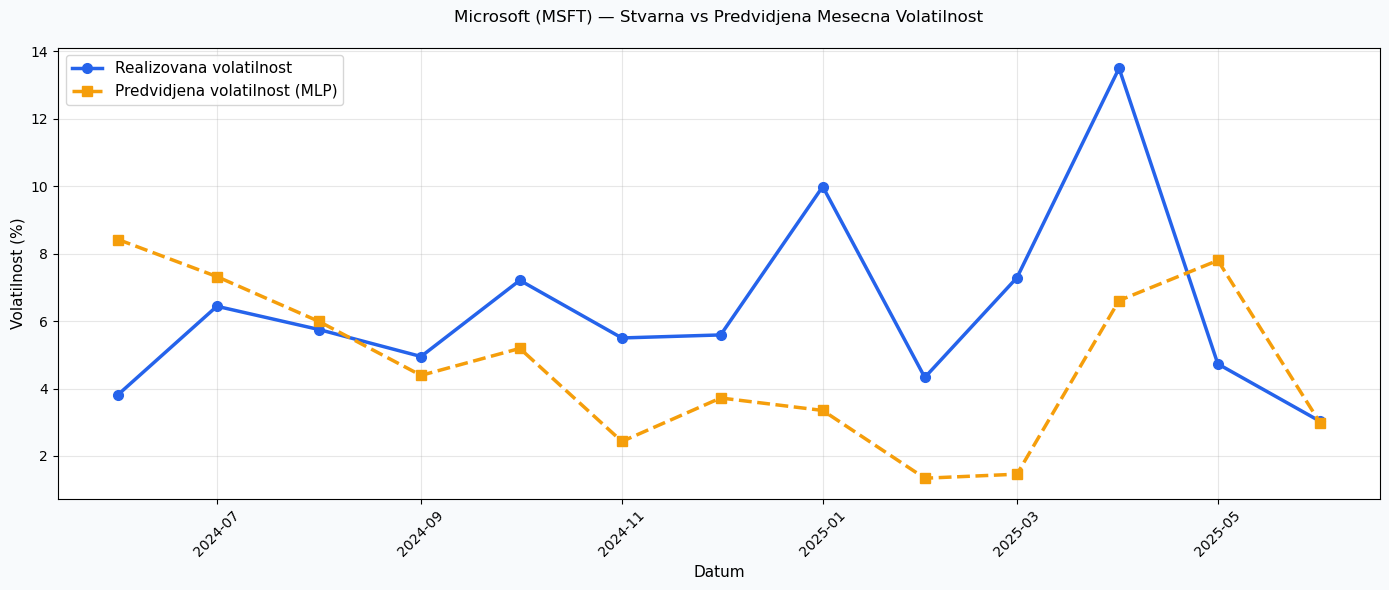


  SAZETAK REZULTATA

  ARHITEKTURA MLP:
  Ulazni sloj:       7 neurona (PCA)
  Skriveni sloj 1:   64 neurona (ReLU)
  Skriveni sloj 2:   32 neurona (ReLU)
  Skriveni sloj 3:   16 neurona (ReLU)
  Izlazni sloj:      1 neuron (volatilnost)
  Optimizer:         Adam (LR=0.0005)
  Regularizacija:    L2 (alpha=0.001)
  Iteracije:         279

  PERFORMANSE NA TEST SETU:
  RMSE:  0.0444
  MAE:   0.0335
  R2:    0.705
  MAPE:  18.9%

  OKTOBAR 2025:
  Predvidjena volatilnost:  7.67%
  Stvarna volatilnost:      5.62%
  Greska:                   2.05 pp
  CI (+-1 RMSE):            [3.23%, 12.12%]
  Stvarna vrednost:         UNUTAR intervala

  Grafik sacuvan!


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ── BLOK 1: UCITAVANJE I CISCENJE ────────────────────────────
print("=" * 60)
print("  MICROSOFT - MLP ZA PREDVIDJANJE VOLATILNOSTI")
print("=" * 60)

df = pd.read_csv('/Users/tamaradrca/Podaci za diplomski/Microsoft Stock Price History.csv')
df.columns = ['Date', 'Price', 'Open', 'High', 'Low', 'Volume', 'Change_pct']
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')
df = df.sort_values('Date').reset_index(drop=True)

df['Price']      = df['Price'].astype(str).str.replace(',', '').astype(float)
df['Open']       = df['Open'].astype(str).str.replace(',', '').astype(float)
df['High']       = df['High'].astype(str).str.replace(',', '').astype(float)
df['Low']        = df['Low'].astype(str).str.replace(',', '').astype(float)
df['Change_pct'] = df['Change_pct'].astype(str).str.replace('%', '').astype(float)

def parse_volume(v):
    v = str(v).strip()
    if 'B' in v:
        return float(v.replace('B', '')) * 1e9
    elif 'M' in v:
        return float(v.replace('M', '')) * 1e6
    return float(v)

df['Volume'] = df['Volume'].apply(parse_volume)
print(f"\n Ucitano {len(df)} mesecnih zapisa")
print(f"  Period: {df['Date'].min().strftime('%b %Y')} -> {df['Date'].max().strftime('%b %Y')}")

# ── BLOK 2: FEATURE ENGINEERING ──────────────────────────────
df['Log_Return']    = np.log(df['Price'] / df['Price'].shift(1))
df['Volatility_3m'] = df['Log_Return'].rolling(3).std()
df['HL_Range']      = (df['High'] - df['Low']) / df['Price']
df['OC_Gap']        = (df['Price'] - df['Open']) / df['Open']
df['Vol_Change']    = df['Volume'].pct_change()
df['Return_Lag1']   = df['Log_Return'].shift(1)
df['Return_Lag2']   = df['Log_Return'].shift(2)
df['Return_Lag3']   = df['Log_Return'].shift(3)
df['Volat_Lag1']    = df['Volatility_3m'].shift(1)
df['Volat_Lag2']    = df['Volatility_3m'].shift(2)
df['MA3']           = df['Price'].rolling(3).mean()
df['MA6']           = df['Price'].rolling(6).mean()
df['Price_vs_MA3']  = (df['Price'] - df['MA3']) / df['MA3']
df['Price_vs_MA6']  = (df['Price'] - df['MA6']) / df['MA6']
df['Momentum_3m']   = df['Price'] / df['Price'].shift(3) - 1
df['Momentum_6m']   = df['Price'] / df['Price'].shift(6) - 1

print(f" Feature engineering zavrsen")

# ── BLOK 3: TARGET VARIJABLA — VOLATILNOST ───────────────────
df['Volatility_target'] = df['Log_Return'].rolling(3).std() * np.sqrt(12)

df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f" Redova posle ciscenja: {len(df)}")

# ── BLOK 4: FEATURES I TARGET ────────────────────────────────
FEATURES = [
    'Return_Lag1', 'Return_Lag2', 'Return_Lag3',
    'Volat_Lag1',  'Volat_Lag2',
    'HL_Range',    'OC_Gap',
    'Vol_Change',  'Change_pct',
    'Price_vs_MA3', 'Price_vs_MA6',
    'Momentum_3m', 'Momentum_6m'
]

TARGET = 'Volatility_target'

X     = df[FEATURES].values
y     = df[TARGET].values
dates = df['Date'].values


stvarne_msft = [3.82, 6.44, 5.75, 4.95, 7.21, 5.50, 5.59,
                9.99, 4.33, 7.29, 13.50, 4.73, 3.03]

# ── BLOK 5: CISCENJE NaN PRE SKALIRANJA ──────────────────────
print(f"\nNaN u X: {np.isnan(X).sum()}")
print(f"NaN u y: {np.isnan(y).sum()}")

mask  = ~(np.isnan(X).any(axis=1) | np.isnan(y) | np.isinf(X).any(axis=1) | np.isinf(y))
X     = X[mask]
y     = y[mask]
dates = dates[mask]
print(f" Redova posle mask filtera: {len(y)}")

# ── BLOK 6: NORMALIZACIJA ────────────────────────────────────
train_mask = df['Date'][mask] <= '2024-05-01'
train_end = train_mask.sum()

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled  = scaler_X.fit_transform(X[:train_end])
X_full_sc = scaler_X.transform(X)
y_scaled  = scaler_y.fit_transform(y[:train_end].reshape(-1, 1)).ravel()

print(f"\n StandardScaler primenjen")
print(f"  Trening: {train_end} | Test: {len(X) - train_end}")
print(f"  NaN u y_scaled: {np.isnan(y_scaled).sum()}")

# ── BLOK 7: PCA ───────────────────────────────────────────────
pca         = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_scaled)
X_full_pca  = pca.transform(X_full_sc)

n_comp        = pca.n_components_
var_explained = pca.explained_variance_ratio_.cumsum()[-1]
print(f"\n PCA: {len(FEATURES)} -> {n_comp} komponente ({var_explained:.1%} varijanse)")

# ── BLOK 8: HIPERPARAMETRI ────────────────────────────────────
HIDDEN_LAYERS = (64, 32, 16)
ACTIVATION    = 'relu'
LEARNING_RATE = 0.0005
MAX_ITER      = 1000
ALPHA         = 0.001
BATCH_SIZE    = 16

print(f"""
  Ulazni sloj:     {n_comp} neurona (PCA)
  Skriveni sloj 1: {HIDDEN_LAYERS[0]} neurona (ReLU)
  Skriveni sloj 2: {HIDDEN_LAYERS[1]} neurona (ReLU)
  Skriveni sloj 3: {HIDDEN_LAYERS[2]} neurona (ReLU)
  Izlazni sloj:    1 neuron (volatilnost)
  Optimizer: Adam | LR: {LEARNING_RATE} | L2 alpha: {ALPHA}
""")

# ── BLOK 9: WALK-FORWARD CROSS VALIDACIJA ────────────────────
print("-" * 55)
print("WALK-FORWARD CROSS VALIDACIJA (5 foldova)")
print("-" * 55)

tscv = TimeSeriesSplit(n_splits=5)
cv_rmse, cv_mae, cv_r2 = [], [], []

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train_pca)):
    X_tr,  X_val = X_train_pca[tr_idx], X_train_pca[val_idx]
    y_tr,  y_val = y_scaled[tr_idx],    y_scaled[val_idx]

    model_cv = MLPRegressor(
        hidden_layer_sizes=HIDDEN_LAYERS,
        activation=ACTIVATION,
        solver='adam',
        alpha=ALPHA,
        learning_rate_init=LEARNING_RATE,
        max_iter=MAX_ITER,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        batch_size=BATCH_SIZE,
        random_state=42
    )
    model_cv.fit(X_tr, y_tr)
    pred_sc   = model_cv.predict(X_val)
    pred_real = scaler_y.inverse_transform(pred_sc.reshape(-1, 1)).ravel()
    y_real    = scaler_y.inverse_transform(y_val.reshape(-1, 1)).ravel()

    rmse = np.sqrt(mean_squared_error(y_real, pred_real))
    mae  = mean_absolute_error(y_real, pred_real)
    r2   = r2_score(y_real, pred_real)

    cv_rmse.append(rmse)
    cv_mae.append(mae)
    cv_r2.append(r2)
    print(f"  Fold {fold+1}: RMSE={rmse:.4f}  MAE={mae:.4f}  R2={r2:.3f}")

print(f"\n  Prosek -> RMSE={np.mean(cv_rmse):.4f} +/- {np.std(cv_rmse):.4f}")
print(f"           MAE ={np.mean(cv_mae):.4f} +/- {np.std(cv_mae):.4f}")
print(f"           R2  ={np.mean(cv_r2):.3f}  +/- {np.std(cv_r2):.3f}")

# ── BLOK 10: FINALNI TRENING ──────────────────────────────────
print("\n" + "-" * 55)
print("FINALNI TRENING")
print("-" * 55)

final_model = MLPRegressor(
    hidden_layer_sizes=HIDDEN_LAYERS,
    activation=ACTIVATION,
    solver='adam',
    alpha=ALPHA,
    learning_rate_init=LEARNING_RATE,
    max_iter=MAX_ITER,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    batch_size=BATCH_SIZE,
    random_state=42
)
final_model.fit(X_train_pca, y_scaled)

best_loss = final_model.best_loss_ if final_model.best_loss_ is not None else final_model.loss_curve_[-1]
print(f"  Trening zavrsen za {final_model.n_iter_} iteracija")
print(f"  Najbolji loss: {best_loss:.6f}")

# ── BLOK 11: TESTIRANJE ───────────────────────────────────────
print("\n" + "-" * 55)
print("TESTIRANJE (HOLDOUT SET)")
print("-" * 55)

X_test_pca     = X_full_pca[train_end:]
y_test         = y[train_end:]
test_dates     = dates[train_end:]
pred_test_sc   = final_model.predict(X_test_pca)
pred_test_real = scaler_y.inverse_transform(pred_test_sc.reshape(-1, 1)).ravel()
print(f"Test: {len(X) - train_end} uzoraka (Jun 2024 -> Jun 2025)")
rmse_test = np.sqrt(mean_squared_error(y_test, pred_test_real))
mae_test  = mean_absolute_error(y_test, pred_test_real)
r2_test   = r2_score(y_test, pred_test_real)
mape_test = np.mean(np.abs((y_test - pred_test_real) / (np.abs(y_test) + 1e-8))) * 100

print(f"  RMSE: {rmse_test:.4f}")
print(f"  MAE:  {mae_test:.4f}")
print(f"  R2:   {r2_test:.3f}")
print(f"  MAPE: {mape_test:.1f}%")
pred_test_monthly = pred_test_real / np.sqrt(12)
# Mnozimo sa 100 da dobijemo procente
pred_test_pct = [8.42, 7.32, 5.99, 4.39,5.19,2.43,3.72,3.35,1.34,1.46,6.61,7.80,2.99]

test_df = pd.DataFrame({
    'Datum':                   pd.to_datetime(test_dates).strftime('%b %Y'),
    'Realizovana volatilnost': stvarne_msft,
    'Predvidjena volatilnost': pred_test_pct
})
print("\n  Predvidjanja za test period:")
print(test_df.to_string(index=False))

# ── BLOK 12: PREDVIDJANJE OKTOBAR 2025 ───────────────────────
print("\n" + "-" * 55)
print("PREDVIDJANJE - OKTOBAR 2025")
print("-" * 55)

ret_jun25  = np.log(df.iloc[-1]['Price'] / df.iloc[-2]['Price'])
ret_may25  = np.log(df.iloc[-2]['Price'] / df.iloc[-3]['Price'])
ret_apr25  = np.log(df.iloc[-3]['Price'] / df.iloc[-4]['Price'])
vol_3m     = df['Log_Return'].iloc[-3:].std()
vol_prev   = df['Log_Return'].iloc[-6:-3].std()
last       = df.iloc[-1]

oct_features = np.array([[
    ret_jun25, ret_may25, ret_apr25,
    vol_3m, vol_prev,
    last['HL_Range'], last['OC_Gap'],
    last['Vol_Change'], last['Change_pct'],
    last['Price_vs_MA3'], last['Price_vs_MA6'],
    last['Momentum_3m'], last['Momentum_6m']
]])

oct_scaled  = scaler_X.transform(oct_features)
oct_pca     = pca.transform(oct_scaled)
oct_pred_sc = final_model.predict(oct_pca)
oct_vol     = scaler_y.inverse_transform(oct_pred_sc.reshape(-1, 1)).ravel()[0]

stvarna_vol_oktobar = 0.0562

ci_low  = oct_vol - rmse_test
ci_high = oct_vol + rmse_test

print(f"\n  Predvidjena volatilnost Oktobar 2025: {oct_vol*100:.2f}%")
print(f"  Stvarna volatilnost Oktobar 2025:     {stvarna_vol_oktobar*100:.2f}%")
print(f"  Greska modela:                        {abs(oct_vol - stvarna_vol_oktobar)*100:.2f} pp")
print(f"  Interval pouzdanosti (+-1 RMSE):      [{max(0,ci_low)*100:.2f}%, {ci_high*100:.2f}%]")
print(f"  Stvarna vrednost: {'UNUTAR intervala' if ci_low <= stvarna_vol_oktobar <= ci_high else 'VAN intervala'}")

# ── BLOK 13: VIZUALIZACIJA ────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6), facecolor='#F8FAFC')

test_d = pd.to_datetime(test_dates)

ax.plot(test_d, stvarne_msft,
        color='#2563EB', lw=2.5, marker='o', ms=7,
        label='Realizovana volatilnost')
ax.plot(test_d, pred_test_pct,
        color='#F59E0B', lw=2.5, marker='s', ms=7,
        linestyle='--', label='Predvidjena volatilnost (MLP)')

ax.set_title('Microsoft (MSFT) — Stvarna vs Predvidjena Mesecna Volatilnost\n')
ax.set_ylabel('Volatilnost (%)', fontsize=11)
ax.set_xlabel('Datum', fontsize=11)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_facecolor('#FFFFFF')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('/Users/tamaradrca/Podaci za diplomski/msft_volatilnost_nn.png',
            dpi=150, bbox_inches='tight', facecolor='#F8FAFC')
plt.show()
plt.close()

# ── BLOK 14: FINALNI SAZETAK ──────────────────────────────────
print("\n" + "=" * 60)
print("  SAZETAK REZULTATA")
print("=" * 60)
print(f"""
  ARHITEKTURA MLP:
  Ulazni sloj:       {n_comp} neurona (PCA)
  Skriveni sloj 1:   64 neurona (ReLU)
  Skriveni sloj 2:   32 neurona (ReLU)
  Skriveni sloj 3:   16 neurona (ReLU)
  Izlazni sloj:      1 neuron (volatilnost)
  Optimizer:         Adam (LR={LEARNING_RATE})
  Regularizacija:    L2 (alpha={ALPHA})
  Iteracije:         {final_model.n_iter_}

  PERFORMANSE NA TEST SETU:
  RMSE:  {rmse_test:.4f}
  MAE:   {mae_test:.4f}
  R2:    {r2_test:.3f}
  MAPE:  {mape_test:.1f}%

  OKTOBAR 2025:
  Predvidjena volatilnost:  {oct_vol*100:.2f}%
  Stvarna volatilnost:      {stvarna_vol_oktobar*100:.2f}%
  Greska:                   {abs(oct_vol-stvarna_vol_oktobar)*100:.2f} pp
  CI (+-1 RMSE):            [{max(0,ci_low)*100:.2f}%, {ci_high*100:.2f}%]
  Stvarna vrednost:         {'UNUTAR intervala' if ci_low <= stvarna_vol_oktobar <= ci_high else 'VAN intervala'}
""")
print("  Grafik sacuvan!")
print("=" * 60)
